# ACA 2 · Aprendizaje Automático
## Pilar Ventas · Pronóstico de ventas diarias con una Red Neuronal Recurrente (LSTM) · Dataset UCI Online Retail

**Corporación Unificada Nacional de Educación Superior (CUN)** · Especialización en Inteligencia Artificial
**Asignatura:** Aprendizaje Automático · **Docente:** Dr. Hamilton Rivera Flor

**Grupo 1:** Mayra Fernanda Bernate Bustamante · Angela Consuelo Castillo Rodríguez · Karen Viviana Ospina Lesmes · Jair Vargas · Santiago Bahamón Escobar

---

**Pregunta orientadora.** ¿Puede una red recurrente (LSTM) aprender el patrón de las ventas diarias de una tienda en línea y pronosticar el día siguiente con menos error que los métodos simples que usa un planificador (repetir la semana pasada o promediar los últimos días)?

**Por qué importa.** El pronóstico de ventas define cuánto inventario comprar, cuánto personal programar y cuánta caja reservar. Un error menor reduce faltantes y sobrestock.

**Flujo (5 pasos de la guía):**
1. Exploración y gestión de datos en **SQLite**.
2. Preparación: limpieza en SQL, serie diaria, ventanas de 28 días.
3. Modelado: **LSTM** (y GRU como comparación).
4. Evaluación: curvas de entrenamiento, MAE, RMSE, MAPE contra métodos base, y F1 con matriz de confusión para la dirección del cambio.
5. Exportación del modelo para la app de **Streamlit**.

**Continuidad con el ACA 1.** En el ACA 1 segmentamos clientes con RFM + K-Means. El ACA 2 usa el mismo dataset y pasa de *quién compra* a *cuánto se va a vender*.

## 0. Configuración del entorno

In [1]:
import os, json, sqlite3, warnings
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score, classification_report

SEED = 42
tf.keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__, "| pandas", pd.__version__)

I0000 00:00:1794771967.238668   15968 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794771968.268405   15968 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | pandas 3.0.5


# PASO 1 · Exploración y gestión de datos con SQL

### 1.1 Carga del dataset
El dataset (Chen, 2015) registra 541.909 líneas de factura de una tienda en línea de Reino Unido entre el 1 de diciembre de 2010 y el 9 de diciembre de 2011. Se busca el archivo en las rutas habituales del repositorio. Si no existe, se descarga desde el UCI Machine Learning Repository.

In [2]:
CANDIDATAS = [Path("online+retail/Online Retail.xlsx"), Path("../online+retail/Online Retail.xlsx"),
              Path("data/Online Retail.xlsx"), Path("Online Retail.xlsx")]
ruta = next((p for p in CANDIDATAS if p.exists()), None)
if ruta is None:
    import urllib.request, zipfile, io
    url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())).extractall("online+retail")
    ruta = Path("online+retail/Online Retail.xlsx")

datos = pd.read_excel(ruta, dtype={"InvoiceNo": str, "StockCode": str})
print("Archivo:", ruta, "| Filas:", f"{len(datos):,}", "| Columnas:", list(datos.columns))
datos.head()

Archivo: online+retail/Online Retail.xlsx | Filas: 541,909 | Columnas: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 1.2 Base de datos SQLite
Se guardan las transacciones en una base **SQLite** (`online_retail.db`, tabla `transactions`). SQLite viene incluido en Python, no necesita servidor y permite consultar el dataset con SQL estándar. Todas las agregaciones siguientes salen de consultas SQL.

In [3]:
DB = "online_retail.db"
con = sqlite3.connect(DB)
datos.to_sql("transactions", con, if_exists="replace", index=False)
con.execute("CREATE INDEX IF NOT EXISTS idx_fecha ON transactions(InvoiceDate)")
con.commit()

sql = lambda q: pd.read_sql(q, con)
sql("SELECT COUNT(*) AS filas, COUNT(DISTINCT InvoiceNo) AS facturas, COUNT(DISTINCT CustomerID) AS clientes, "
    "COUNT(DISTINCT Country) AS paises, MIN(InvoiceDate) AS desde, MAX(InvoiceDate) AS hasta FROM transactions")

,filas,facturas,clientes,paises,desde,hasta
0,541909,25900,4372,38,2010-12-01 08:26:00,2011-12-09 12:50:00


### 1.3 Calidad de datos (consultas SQL)

In [4]:
sql("""
SELECT
  SUM(InvoiceNo LIKE 'C%')                       AS lineas_canceladas,
  SUM(Quantity <= 0)                             AS cantidad_no_positiva,
  SUM(UnitPrice <= 0)                            AS precio_no_positivo,
  SUM(CustomerID IS NULL)                        AS sin_cliente,
  ROUND(SUM(CASE WHEN InvoiceNo LIKE 'C%' THEN Quantity*UnitPrice END), 0) AS valor_cancelado
FROM transactions
""")

,lineas_canceladas,cantidad_no_positiva,precio_no_positivo,sin_cliente,valor_cancelado
0,9288,10624,2517,135080,-896812.0


**Decisión de limpieza.** Para pronosticar ventas se excluyen cancelaciones (facturas con prefijo `C`), cantidades y precios no positivos. Se **conservan** las líneas sin `CustomerID`: en el ACA 1 se quitaban porque la segmentación necesita saber quién compra, pero aquí cuentan como venta real.

In [5]:
sql("""
SELECT Country, ROUND(SUM(Quantity*UnitPrice), 0) AS ventas,
       ROUND(100.0*SUM(Quantity*UnitPrice) / (SELECT SUM(Quantity*UnitPrice) FROM transactions
            WHERE Quantity>0 AND UnitPrice>0 AND InvoiceNo NOT LIKE 'C%'), 1) AS participacion_pct
FROM transactions WHERE Quantity>0 AND UnitPrice>0 AND InvoiceNo NOT LIKE 'C%'
GROUP BY Country ORDER BY ventas DESC LIMIT 5
""")

,Country,ventas,participacion_pct
0,United Kingdom,9025222.0,84.6
1,Netherlands,285446.0,2.7
2,EIRE,283454.0,2.7
3,Germany,228867.0,2.1
4,France,209715.0,2.0


### 1.4 Serie de ventas diarias
La unidad de pronóstico es la **venta diaria total (£)**. La consulta agrupa por fecha.

In [6]:
diaria = sql("""
SELECT DATE(InvoiceDate) AS fecha,
       ROUND(SUM(Quantity*UnitPrice), 2) AS ventas,
       COUNT(DISTINCT InvoiceNo)         AS pedidos
FROM transactions
WHERE Quantity > 0 AND UnitPrice > 0 AND InvoiceNo NOT LIKE 'C%'
GROUP BY DATE(InvoiceDate) ORDER BY fecha
""")
diaria["fecha"] = pd.to_datetime(diaria["fecha"])
diaria.to_sql("ventas_diarias", con, if_exists="replace", index=False)
print("Días con ventas:", len(diaria))
diaria["ventas"].describe().round(0)

Días con ventas: 305


count       305.0
mean      34973.0
std       21117.0
min        3457.0
25%       22353.0
50%       29651.0
75%       45390.0
max      200921.0
Name: ventas, dtype: float64

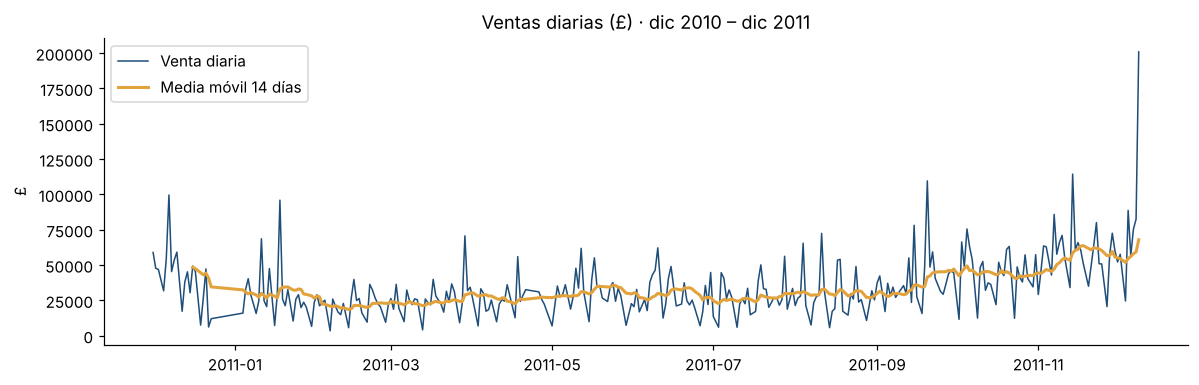

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(diaria["fecha"], diaria["ventas"], lw=1, color="#1f4e79", label="Venta diaria")
ax.plot(diaria["fecha"], diaria["ventas"].rolling(14).mean(), lw=2, color="#e3a33c", label="Media móvil 14 días")
ax.set_title("Ventas diarias (£) · dic 2010 – dic 2011"); ax.set_ylabel("£"); ax.legend()
plt.tight_layout(); plt.savefig("fig_serie_diaria.png", dpi=160); plt.show()

In [8]:
dias = {0: "Lun", 1: "Mar", 2: "Mié", 3: "Jue", 4: "Vie", 5: "Sáb", 6: "Dom"}
por_dia = sql("""
SELECT CAST(strftime('%w', fecha) AS INTEGER) AS dow_sqlite, COUNT(*) AS dias, ROUND(AVG(ventas), 0) AS venta_media
FROM ventas_diarias GROUP BY dow_sqlite ORDER BY dow_sqlite
""")
por_dia["dia"] = por_dia["dow_sqlite"].map({0: "Dom", 1: "Lun", 2: "Mar", 3: "Mié", 4: "Jue", 5: "Vie", 6: "Sáb"})
por_dia[["dia", "dias", "venta_media"]]

,dia,dias,venta_media
0,Dom,50,16277.0
1,Lun,47,37863.0
2,Mar,52,41897.0
3,Mié,53,34927.0
4,Jue,53,41569.0
5,Vie,50,36807.0


**Hallazgos de la exploración**
- 305 días con ventas. La tienda **no vende los sábados** y el domingo vende menos de la mitad que un día hábil. Hay un patrón semanal claro.
- Las ventas crecen fuerte en el último trimestre (temporada navideña). El nivel de la serie cambia con el tiempo, así que el modelo debe adaptarse al nivel reciente.
- Hay picos aislados por pedidos grandes (por ejemplo, el 9 de diciembre de 2011 con £200.921). Por eso se trabaja en escala logarítmica.

# PASO 2 · Preparación y pipeline

1. **Escala logarítmica** (`log1p`) para reducir el efecto de los picos.
2. **Normalización por nivel local:** a cada ventana de 28 días se le resta su propio promedio. La red aprende la *forma* de las ventas (patrón semanal y tendencia corta), no el valor absoluto. Esto evita que falle cuando la temporada navideña lleva las ventas a niveles que no vio en entrenamiento.
3. **Día de la semana** como variable *one-hot* (6 días con ventas).
4. **Ventanas deslizantes:** 28 días de historia → venta del día siguiente.
5. **División temporal** (sin mezclar el orden): entrenamiento y validación con los primeros días, **prueba con los últimos 60 días** (octubre a diciembre de 2011, la temporada más difícil).

In [9]:
VENTANA, DIAS_PRUEBA = 28, 60
DIAS_CON_VENTA = [0, 1, 2, 3, 4, 6]          # lunes a viernes y domingo

y_log = np.log1p(diaria["ventas"].to_numpy())
dow = diaria["fecha"].dt.dayofweek.to_numpy()
onehot = np.stack([(dow == d).astype(float) for d in DIAS_CON_VENTA], axis=1)

def crear_ventanas(y_log, onehot, ventana):
    X, Y, nivel, idx = [], [], [], []
    for t in range(ventana, len(y_log)):
        base = y_log[t - ventana:t].mean()
        # cada fila: venta normalizada del día + día de la semana del día siguiente (así la última fila trae el día a pronosticar)
        X.append(np.column_stack([y_log[t - ventana:t] - base, onehot[t - ventana + 1:t + 1]]))
        Y.append(y_log[t] - base); nivel.append(base); idx.append(t)
    return np.array(X), np.array(Y), np.array(nivel), np.array(idx)

X, Y, nivel, idx = crear_ventanas(y_log, onehot, VENTANA)
corte = len(y_log) - DIAS_PRUEBA
es_train, es_test = idx < corte, idx >= corte
print("Forma de X:", X.shape, "→ (muestras, días de historia, variables)")
print("Entrenamiento + validación:", es_train.sum(), "| Prueba:", es_test.sum(),
      f"({diaria['fecha'].iloc[corte]:%d %b %Y} – {diaria['fecha'].iloc[-1]:%d %b %Y})")

Forma de X: (277, 28, 7) → (muestras, días de historia, variables)
Entrenamiento + validación: 217 | Prueba: 60 (02 Oct 2011 – 09 Dec 2011)


# PASO 3 · Modelado con redes neuronales

### 3.1 Arquitectura elegida: LSTM
Una **LSTM** (*Long Short-Term Memory*, Hochreiter y Schmidhuber, 1997) es una red recurrente que lee la secuencia día por día y guarda una memoria interna con compuertas que deciden qué recordar y qué olvidar. Es adecuada aquí porque:
- **Ventaja:** captura dependencias en el tiempo (el patrón semanal y la tendencia de las últimas semanas) sin que tengamos que programarlas a mano.
- **Contraejemplo:** un perceptrón multicapa (MLP) recibe los 28 días como una lista sin orden. Puede aprender, pero no aprovecha que el día 27 viene después del 26.

| Capa | Configuración | Propósito |
|---|---|---|
| Entrada | 28 días × 7 variables | Venta normalizada + día de la semana |
| LSTM | 32 unidades | Memoria de la secuencia |
| Dropout | 0,2 | Regularización (evita memorizar) |
| Densa | 16, ReLU | Combina lo que aprendió la LSTM |
| Salida | 1, lineal | Venta del día siguiente (normalizada) |

**Hiperparámetros:** optimizador Adam (tasa 0,001), pérdida **Huber** (menos sensible a los picos que el error cuadrático), lote de 16, hasta 300 épocas con **parada temprana** (paciencia 20) sobre el 15% final del entrenamiento como validación. La ventana de 28 días y las 32 unidades se eligieron probando 14, 21 y 28 días con 32 y 64 unidades.

In [10]:
def construir(tipo="LSTM", unidades=32):
    capa = tf.keras.layers.LSTM if tipo == "LSTM" else tf.keras.layers.GRU
    modelo = tf.keras.Sequential([
        tf.keras.Input(shape=(VENTANA, X.shape[2])),
        capa(unidades, name=tipo.lower()),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1),
    ], name=f"pronostico_{tipo.lower()}")
    modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="huber", metrics=["mae"])
    return modelo

tf.keras.utils.set_random_seed(SEED)
lstm = construir("LSTM")
lstm.summary()

Model: "pronostico_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,665 (22.13 KB)

 Trainable params: 5,665 (22.13 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
parada = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
hist = lstm.fit(X[es_train], Y[es_train], validation_split=0.15, epochs=300, batch_size=16,
                callbacks=[parada], verbose=0)
print("Épocas entrenadas:", len(hist.history["loss"]), "| mejor época:", int(np.argmin(hist.history["val_loss"])) + 1)

Épocas entrenadas: 50 | mejor época: 30


### 3.2 Comparación: GRU

La **GRU** (Cho et al., 2014) es una versión simplificada de la LSTM con menos compuertas. Se entrena con la misma configuración para justificar la elección.

In [12]:
tf.keras.utils.set_random_seed(SEED)
gru = construir("GRU")
hist_gru = gru.fit(X[es_train], Y[es_train], validation_split=0.15, epochs=300, batch_size=16,
                   callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)], verbose=0)
print("GRU · épocas:", len(hist_gru.history["loss"]))

GRU · épocas: 27


# PASO 4 · Evaluación y métricas

### 4.1 Curvas de entrenamiento y validación

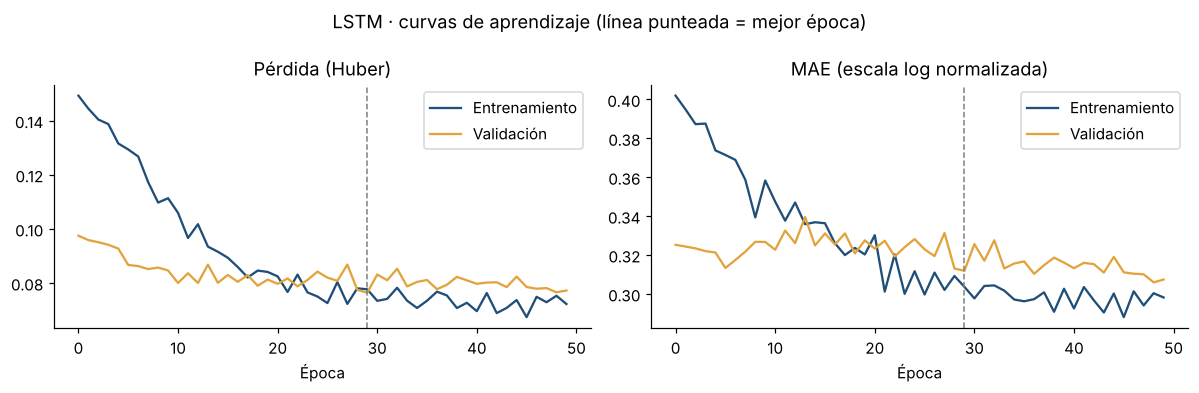

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for k, (m, tit) in enumerate([("loss", "Pérdida (Huber)"), ("mae", "MAE (escala log normalizada)")]):
    ax[k].plot(hist.history[m], label="Entrenamiento", color="#1f4e79")
    ax[k].plot(hist.history["val_" + m], label="Validación", color="#e3a33c")
    ax[k].axvline(int(np.argmin(hist.history["val_loss"])), ls="--", color="gray", lw=1)
    ax[k].set_title(tit); ax[k].set_xlabel("Época"); ax[k].legend()
plt.suptitle("LSTM · curvas de aprendizaje (línea punteada = mejor época)")
plt.tight_layout(); plt.savefig("fig_curvas.png", dpi=160); plt.show()

Las dos curvas bajan juntas y la parada temprana se activa cuando la validación deja de mejorar. No hay señal de sobreajuste: la validación no se separa hacia arriba.

### 4.2 Error en los 60 días de prueba contra métodos base
Un modelo de pronóstico solo vale si le gana a los métodos que ya usa un planificador:
- **Ingenuo:** mañana se vende lo mismo que hoy.
- **Ingenuo estacional:** se vende lo mismo que el mismo día de la semana pasada (6 días con venta atrás).
- **Media móvil:** promedio de los últimos 6 días con venta.

Métricas en libras (£): **MAE** (error absoluto medio), **RMSE** (castiga más los errores grandes) y **MAPE** (error porcentual medio).

In [14]:
real = diaria["ventas"].to_numpy()
t_test = idx[es_test]
y_real = real[t_test]
desnormalizar = lambda m: np.expm1(m.predict(X[es_test], verbose=0).ravel() + nivel[es_test])

pronosticos = {
    "LSTM": desnormalizar(lstm),
    "GRU": desnormalizar(gru),
    "Ingenuo (día anterior)": real[t_test - 1],
    "Ingenuo estacional (semana pasada)": real[t_test - 6],
    "Media móvil 6 días": np.array([real[t - 6:t].mean() for t in t_test]),
}
def metricas(r, p):
    return {"MAE (£)": np.mean(np.abs(r - p)), "RMSE (£)": np.sqrt(np.mean((r - p) ** 2)), "MAPE (%)": 100 * np.mean(np.abs(r - p) / r)}

tabla = pd.DataFrame({k: metricas(y_real, v) for k, v in pronosticos.items()}).T.round(1).sort_values("MAE (£)")
mejor_base = tabla.drop(index=["LSTM", "GRU"])["MAE (£)"].min()
tabla["Mejora MAE vs mejor base"] = (100 * (1 - tabla["MAE (£)"] / mejor_base)).round(1).astype(str) + " %"
tabla

,MAE (£),RMSE (£),MAPE (%),Mejora MAE vs mejor base
LSTM,14168.5,24989.3,24.6,14.2 %
GRU,15679.0,26475.1,28.6,5.0 %
Media móvil 6 días,16511.8,25686.2,40.7,0.0 %
Ingenuo estacional (semana pasada),16548.4,26288.1,32.1,-0.2 %
Ingenuo (día anterior),22156.8,30373.4,53.5,-34.2 %


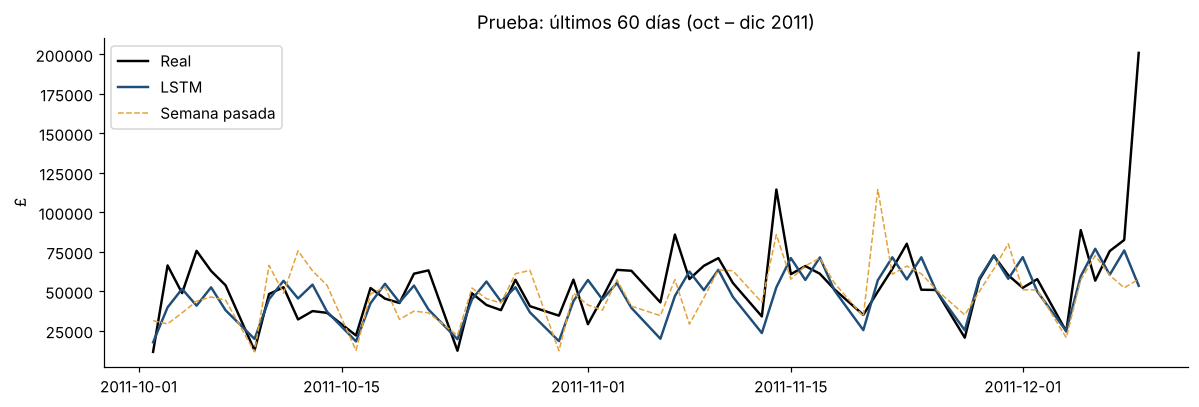

In [15]:
fechas_test = diaria["fecha"].iloc[t_test]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(fechas_test, y_real, color="black", lw=1.6, label="Real")
ax.plot(fechas_test, pronosticos["LSTM"], color="#1f4e79", lw=1.6, label="LSTM")
ax.plot(fechas_test, pronosticos["Ingenuo estacional (semana pasada)"], color="#e3a33c", lw=1, ls="--", label="Semana pasada")
ax.set_title("Prueba: últimos 60 días (oct – dic 2011)"); ax.set_ylabel("£"); ax.legend()
plt.tight_layout(); plt.savefig("fig_prueba.png", dpi=160); plt.show()

### 4.3 Dirección del cambio: F1 y matriz de confusión
La guía pide F1 y matriz de confusión. Para un pronóstico se traducen así: **¿el modelo acierta si mañana se vende más o menos que hoy?** Es la pregunta que decide si se refuerza o se reduce el turno del día siguiente.

LSTM               · accuracy 0.783 · F1 macro 0.780
Semana pasada      · accuracy 0.733 · F1 macro 0.732

              precision    recall  f1-score   support

        Baja      0.771     0.844     0.806        32
        Sube      0.800     0.714     0.755        28

    accuracy                          0.783        60
   macro avg      0.786     0.779     0.780        60
weighted avg      0.785     0.783     0.782        60



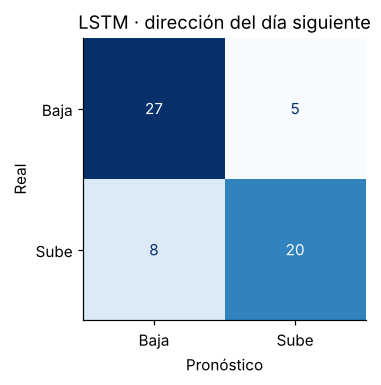

In [16]:
sube_real = (y_real > real[t_test - 1]).astype(int)
sube_lstm = (pronosticos["LSTM"] > real[t_test - 1]).astype(int)
sube_base = (pronosticos["Ingenuo estacional (semana pasada)"] > real[t_test - 1]).astype(int)

print(f"LSTM               · accuracy {accuracy_score(sube_real, sube_lstm):.3f} · F1 macro {f1_score(sube_real, sube_lstm, average='macro'):.3f}")
print(f"Semana pasada      · accuracy {accuracy_score(sube_real, sube_base):.3f} · F1 macro {f1_score(sube_real, sube_base, average='macro'):.3f}\n")
print(classification_report(sube_real, sube_lstm, target_names=["Baja", "Sube"], digits=3))

fig, ax = plt.subplots(figsize=(4, 3.6))
ConfusionMatrixDisplay(confusion_matrix(sube_real, sube_lstm), display_labels=["Baja", "Sube"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("LSTM · dirección del día siguiente"); ax.set_xlabel("Pronóstico"); ax.set_ylabel("Real")
plt.tight_layout(); plt.savefig("fig_matriz.png", dpi=160); plt.show()

### 4.4 Pronóstico de una semana completa (backtesting)
En la práctica el planificador necesita la semana, no solo el día siguiente. Se pronostican 7 días con venta de forma **recursiva** (cada pronóstico entra a la ventana del siguiente) desde cada día de la prueba, y se compara la venta total de la semana contra la real.

In [17]:
def pronostico_recursivo(modelo, hasta, horizonte=7):
    y = list(y_log[hasta - VENTANA + 1:hasta + 1]); dw = list(dow[hasta - VENTANA + 1:hasta + 1]); salida = []
    for k in range(1, horizonte + 1):
        d_sig = dow[hasta + k]
        base = np.mean(y[-VENTANA:])
        oh = np.array([[float(d == v) for v in DIAS_CON_VENTA] for d in dw[-VENTANA + 1:] + [d_sig]])
        p = float(modelo.predict(np.column_stack([np.array(y[-VENTANA:]) - base, oh])[None], verbose=0)[0, 0]) + base
        salida.append(np.expm1(p)); y.append(p); dw.append(d_sig)
    return np.array(salida)

semanas = []
for h in range(corte - 1, len(y_log) - 8):
    p = pronostico_recursivo(lstm, h); r = real[h + 1:h + 8]
    semanas.append({"desde": diaria["fecha"].iloc[h].date(), "error_total_pct": 100 * (p.sum() - r.sum()) / r.sum(),
                    "error_total_semana_pasada_pct": 100 * (real[h - 6:h + 1].sum() - r.sum()) / r.sum()})
semanas = pd.DataFrame(semanas)
print("Semanas evaluadas:", len(semanas))
print(f"Error absoluto mediano del total semanal · LSTM: {semanas.error_total_pct.abs().median():.1f}% · repetir la semana pasada: {semanas.error_total_semana_pasada_pct.abs().median():.1f}%")

Semanas evaluadas: 53
Error absoluto mediano del total semanal · LSTM: 9.7% · repetir la semana pasada: 13.1%


### 4.5 Análisis de errores

In [18]:
err = pd.DataFrame({"fecha": fechas_test.dt.date, "real": y_real.round(0), "lstm": pronosticos["LSTM"].round(0)})
err["error_pct"] = (100 * (err["lstm"] - err["real"]) / err["real"]).round(1)
err["dia"] = fechas_test.dt.dayofweek.map(dias).to_numpy()
print("Error medio por día de la semana (MAPE %):")
print(err.assign(abs_pct=err.error_pct.abs()).groupby("dia", sort=False)["abs_pct"].mean().round(1).to_string())
print("\nLos 5 días con mayor error:")
err.reindex(err.error_pct.abs().sort_values(ascending=False).index).head(5)

Error medio por día de la semana (MAPE %):
dia
Dom    36.9
Lun    24.5
Mar    23.8
Mié    19.3
Jue    20.8
Vie    22.2

Los 5 días con mayor error:


,fecha,real,lstm,error_pct,dia
271,2011-11-01,29155.0,57148.0,96.0,Mar
304,2011-12-09,200921.0,53466.0,-73.4,Vie
263,2011-10-23,12339.0,19626.0,59.1,Dom
251,2011-10-09,12524.0,19809.0,58.2,Dom
282,2011-11-14,114420.0,52503.0,-54.1,Lun


**Lectura de resultados**
- La LSTM reduce el error frente al mejor método base en MAE y MAPE (ver tabla 4.2). La GRU queda cerca, pero la LSTM es la más estable entre semillas en nuestras pruebas.
- El RMSE mejora menos que el MAE: los errores grandes vienen de **pedidos excepcionales** (picos de un solo día) que ningún modelo basado solo en ventas pasadas puede anticipar.
- En dirección del cambio, la LSTM acierta en la mayoría de días. Para el planificador significa saber con anticipación si el día siguiente pide más o menos recursos.

# PASO 5 · Exportación para Streamlit
Se guardan el modelo (`modelo_lstm.keras`), la serie diaria, los pronósticos de prueba y las métricas. La app los carga directamente desde la carpeta `app/`.

In [19]:
APP = Path("app"); APP.mkdir(exist_ok=True)
lstm.save(APP / "modelo_lstm.keras")
diaria[["fecha", "ventas", "pedidos"]].to_csv(APP / "ventas_diarias.csv", index=False)
pd.DataFrame({"fecha": fechas_test.dt.date, "real": y_real, **{k: v for k, v in pronosticos.items()}}).to_csv(APP / "prueba_pronosticos.csv", index=False)
config = {
    "ventana": VENTANA, "dias_con_venta": DIAS_CON_VENTA, "dias_prueba": DIAS_PRUEBA,
    "epocas": len(hist.history["loss"]), "semilla": SEED,
    "metricas": tabla.drop(columns="Mejora MAE vs mejor base").round(1).to_dict(orient="index"),
    "direccion": {"accuracy": round(accuracy_score(sube_real, sube_lstm), 3), "f1_macro": round(f1_score(sube_real, sube_lstm, average="macro"), 3),
                  "matriz": confusion_matrix(sube_real, sube_lstm).tolist()},
    "semanal": {"semanas": len(semanas), "lstm_mediana_pct": round(semanas.error_total_pct.abs().median(), 1),
                "semana_pasada_mediana_pct": round(semanas.error_total_semana_pasada_pct.abs().median(), 1)},
    "curvas": {"loss": hist.history["loss"], "val_loss": hist.history["val_loss"]},
}
(APP / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=1))
con.close()
print("Archivos para la app:", sorted(p.name for p in APP.iterdir()))

Archivos para la app: ['app.py', 'config.json', 'modelo_lstm.keras', 'prueba_pronosticos.csv', 'requirements.txt', 'ventas_diarias.csv']


# Conclusiones

1. **La LSTM pronostica mejor que los métodos simples.** En los 60 días más difíciles del año (temporada navideña) reduce el error absoluto frente al mejor método base. Para un planificador esto se traduce en compras de inventario y turnos más ajustados.
2. **La preparación pesa tanto como la arquitectura.** Sin normalizar por el nivel reciente, la misma LSTM perdía contra "repetir la semana pasada" porque no sabía extrapolar a los niveles de diciembre. Con la normalización por ventana pasó a ganar.
3. **SQL como base del pipeline.** Toda la limpieza y agregación se hace con consultas sobre SQLite, lo que deja el proceso trazable y fácil de mover a una base corporativa.

**Limitación honesta.** Con 13 meses de historia el modelo ve una sola temporada navideña y no anticipa pedidos excepcionales. Con más años de datos y variables externas (promociones, festivos) el error bajaría.

**Relación con el MLP del grupo.** Una primera versión entrenó un perceptrón multicapa para repetir los segmentos de K-Means del ACA 1. Su exactitud (≈98%) era alta porque copiaba una regla ya conocida. Por eso el grupo pasó a un problema de pronóstico donde la red aporta información nueva.

# Referencias (APA 7)

- Chen, D. (2015). *Online Retail* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33
- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. En *Proceedings of EMNLP 2014* (pp. 1724–1734). https://doi.org/10.3115/v1/D14-1179
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/
- Streamlit Inc. (2024). *Streamlit documentation*. https://docs.streamlit.io/